# Phân cụm K-Means (K-Means Clustering)

K-Means là thuật toán học không giám sát phân mảnh tập dữ liệu thành $K$ cụm rời rạc. Thuật toán này tối ưu hóa việc phân chia bằng cách thu nhỏ **Tổng bình phương khoảng cách nội cụm (Within-Cluster Sum of Squares - WCSS / Inertia)**.

**1. Hàm mục tiêu (Objective Function):**
$$J = \sum_{j=1}^K \sum_{i \in C_j} || x_i - \mu_j ||^2$$
Trong đó: $C_j$ là tập hợp các điểm thuộc cụm $j$, và $\mu_j$ là tâm (centroid) của cụm $j$.

**2. Thuật toán Lloyd (Kỳ vọng - Cực đại hóa đơn giản):**
Bởi vì việc tìm nghiệm tối ưu tuyệt đối (Global Minimum) cho K-Means là một bài toán NP-Hard, thuật toán sử dụng phương pháp lặp để xấp xỉ cực tiểu cục bộ:
*   **Khởi tạo:** Chọn ngẫu nhiên $K$ điểm trong tập dữ liệu làm tâm cụm ban đầu.
*   **Bước Gán (Expectation):** Gán mỗi điểm dữ liệu vào tâm cụm gần nhất (đo bằng khoảng cách Euclidean).
*   **Bước Cập nhật (Maximization):** Dịch chuyển tâm cụm đến vị trí trung bình cộng (mean) tọa độ của tất cả các điểm vừa được gán vào nó.
*   **Điều kiện dừng:** Lặp lại 2 bước trên cho đến khi các tâm cụm không còn dịch chuyển (hội tụ).

In [1]:
import numpy as np
from utils.distances import euclidean_distance_matrix

class KMeansScratch:
    """Thuật toán K-Means sử dụng hàm tính khoảng cách Ma trận tối ưu tốc độ."""
    def __init__(self, k=3, max_iters=100, random_state=42):
        self.k = k
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X: np.ndarray):
        X = np.asarray(X)
        np.random.seed(self.random_state)
        
        # 1. Khởi tạo ngẫu nhiên K tâm cụm từ chính dữ liệu gốc
        random_idx = np.random.choice(X.shape[0], self.k, replace=False)
        self.centroids = X[random_idx]

        for _ in range(self.max_iters):
            # 2. Bước Gán: Tính khoảng cách Euclidean ma trận và gán nhãn
            # distances.shape = (n_samples, K)
            distances = euclidean_distance_matrix(X, self.centroids)
            new_labels = np.argmin(distances, axis=1)

            # 3. Bước Cập nhật: Tính tọa độ trung bình mới cho các tâm cụm
            new_centroids = np.zeros_like(self.centroids)
            for i in range(self.k):
                cluster_points = X[new_labels == i]
                if len(cluster_points) > 0:
                    new_centroids[i] = cluster_points.mean(axis=0)
                else:
                    # Chống chết cụm (Empty Cluster) bằng cách giữ nguyên
                    new_centroids[i] = self.centroids[i]

            # Kiểm tra hội tụ (Centroids không dịch chuyển)
            if np.all(self.centroids == new_centroids):
                self.labels = new_labels
                break
                
            self.centroids = new_centroids
            self.labels = new_labels
            
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        distances = euclidean_distance_matrix(np.asarray(X), self.centroids)
        return np.argmin(distances, axis=1)

Metric               | Scratch         | Sklearn        
-------------------------------------------------------
Time (ms)            | 0.00            | 40.10          


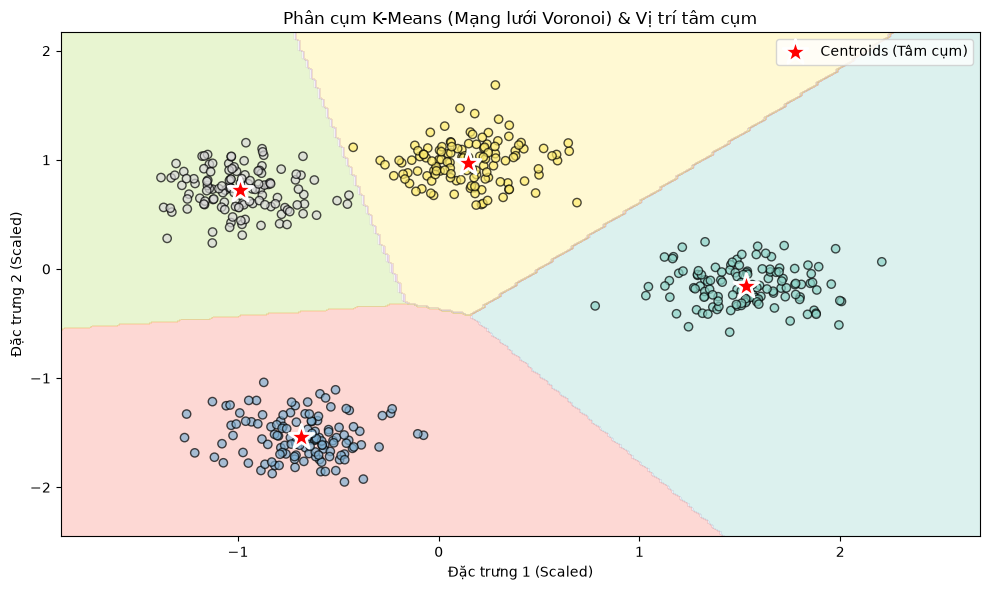

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from utils.preprocessing import StandardScaler

# 1. Sinh dữ liệu không nhãn (Tạo 4 cụm)
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=1.2, random_state=42)

# Chuẩn hóa dữ liệu là bắt buộc với các thuật toán dựa trên Khoảng cách (như K-Means, KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Chạy model Scratch
t0 = time.time()
model_scratch = KMeansScratch(k=4, random_state=42).fit(X_scaled)
t_scratch = (time.time() - t0) * 1000

# 3. Chạy model Sklearn (n_init="auto" theo chuẩn mới)
t0 = time.time()
model_sklearn = KMeans(n_clusters=4, random_state=42, n_init="auto").fit(X_scaled)
t_sklearn = (time.time() - t0) * 1000

print(f"{'Metric':<20} | {'Scratch':<15} | {'Sklearn':<15}")
print("-" * 55)
print(f"{'Time (ms)':<20} | {t_scratch:<15.2f} | {t_sklearn:<15.2f}")
# Lưu ý: Không dùng Accuracy Score vì đây là học Không giám sát (Nhãn cluster có thể bị hoán vị)

# 4. Trực quan hóa ranh giới Voronoi của K-Means
plt.figure(figsize=(10, 6))

x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = model_scratch.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='Set3')
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=model_scratch.labels, cmap='Set3', edgecolors='k', alpha=0.7)

# Vẽ tâm cụm (Centroids)
centroids = model_scratch.centroids
plt.scatter(centroids[:, 0], centroids[:, 1], marker='*', s=350, c='red', edgecolors='white', linewidths=2, label="Centroids (Tâm cụm)")

plt.title("Phân cụm K-Means (Mạng lưới Voronoi) & Vị trí tâm cụm")
plt.xlabel("Đặc trưng 1 (Scaled)")
plt.ylabel("Đặc trưng 2 (Scaled)")
plt.legend()
plt.tight_layout()
plt.show()